## 5. Model Tournament Comparison (5-Fold CV on Development Split Only)

In [13]:
baseline_pipeline = Pipeline(steps=[
    ('engineering', HouseFeatureEngineer()),
    ('preprocessor', clone(preprocessor)),
    ('model', DummyRegressor(strategy='median'))
])

baseline_scores = -1 * cross_val_score(
    baseline_pipeline, X_dev, y_dev,
    cv=cv,
    scoring='neg_mean_absolute_error'
)

print(f"Naive Median Baseline MAE across 5 CV Folds on X_dev: ${baseline_scores.mean():,.2f} (Std: ${baseline_scores.std():,.2f})")

Naive Median Baseline MAE across 5 CV Folds on X_dev: $54,586.14 (Std: $2,676.56)


### Five-Model Screening Tournament and Shared CV Evaluator
We benchmark five distinct algorithm families under identical 5-fold cross-validation on `X_dev`:
1. **Linear Regression** (Ordinary Least Squares baseline)
2. **Support Vector Regressor (SVR)** (Kernel-based margin optimization, baseline comparison only)
3. **Random Forest Regressor** (Bagged decision trees)
4. **XGBoost Regressor** (Gradient boosted trees with second-order gradients)
5. **Gradient Boosting Regressor** (Sequential residual boosting)

In [14]:
scoring = {
    'MAE': 'neg_mean_absolute_error',
    'MSE': 'neg_mean_squared_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2',
}

candidate_templates = {}
candidate_cv_results = {}
candidate_eligible = {}

def evaluate_candidate(name, estimator, eligible=True):
    scores = cross_validate(clone(estimator), X_dev, y_dev, cv=cv, scoring=scoring, n_jobs=-1, error_score='raise')

    mae_mean = -scores['test_MAE'].mean()
    mae_std = scores['test_MAE'].std()
    mse_mean = -scores['test_MSE'].mean()
    rmse_mean = -scores['test_RMSE'].mean()
    r2_mean = scores['test_R2'].mean()

    candidate_templates[name] = estimator
    candidate_cv_results[name] = {
        'Model': name,
        'CV MAE Mean': mae_mean,
        'CV MAE Std': mae_std,
        'CV MSE Mean': mse_mean,
        'CV RMSE Mean': rmse_mean,
        'CV R2 Mean': r2_mean
    }
    candidate_eligible[name] = eligible
    print(f"Evaluated: {name} | CV MAE: ${mae_mean:,.2f} (Std: ${mae_std:,.2f})")

selection_step = SelectFromModel(Lasso(alpha=100, max_iter=10000, tol=0.01, random_state=42))

models = {
    'Linear Regression': LinearRegression(),
    'Support Vector Regressor (SVR)': SVR(),
    'Random Forest': RandomForestRegressor(random_state=42),
    'XGBoost': xgb.XGBRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}

print("=== MODEL TOURNAMENT SCREENING ===")
for name, model_obj in models.items():
    pipe = Pipeline(steps=[
        ('engineering', HouseFeatureEngineer()),
        ('preprocessor', clone(preprocessor)),
        ('selection', clone(selection_step)),
        ('model', model_obj)
    ])
    evaluate_candidate(name, pipe)

screening_winner_name = min([name for name, res in candidate_cv_results.items() if candidate_eligible[name]],
                            key=lambda x: candidate_cv_results[x]['CV MAE Mean'])
print(f"Screening Winner Model Family: {screening_winner_name}")

=== MODEL TOURNAMENT SCREENING ===
Evaluated: Linear Regression | CV MAE: $17,789.93 (Std: $1,315.17)
Evaluated: Support Vector Regressor (SVR) | CV MAE: $54,585.41 (Std: $2,676.36)
Evaluated: Random Forest | CV MAE: $17,306.85 (Std: $1,280.49)
Evaluated: XGBoost | CV MAE: $17,909.64 (Std: $971.10)
Evaluated: Gradient Boosting | CV MAE: $15,604.97 (Std: $708.58)
Screening Winner Model Family: Gradient Boosting


## 7. Model Stacking Benchmark (Development-Only Benchmark)

In [17]:
estimators = [
    ('rf', Pipeline(steps=[('pre', clone(preprocessor)), ('model', RandomForestRegressor(n_estimators=100, random_state=42))])),
    ('xgb', Pipeline(steps=[('pre', clone(preprocessor)), ('model', xgb.XGBRegressor(n_estimators=100, learning_rate=0.05, random_state=42))])),
    ('gb', Pipeline(steps=[('pre', clone(preprocessor)), ('model', GradientBoostingRegressor(n_estimators=100, random_state=42))]))
]

stacking_model = StackingRegressor(
    estimators=estimators,
    final_estimator=Lasso(alpha=100),
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=1
)

stacking_pipeline = Pipeline(steps=[
    ('engineering', HouseFeatureEngineer()),
    ('model', stacking_model)
])

evaluate_candidate("Stacking Regressor (Benchmark Only)", stacking_pipeline, eligible=False)

Evaluated: Stacking Regressor (Benchmark Only) | CV MAE: $16,154.52 (Std: $1,475.82)


## 8. Hyperparameter Optimization: RandomizedSearchCV vs. GridSearchCV Benchmark

To identify the optimal hyperparameters for our tournament screening winner (`Gradient Boosting`), we conduct a scientifically controlled benchmark between two optimization methodologies on the development partition (`X_dev`):
1. **GridSearchCV (Exhaustive Search):** Rigorously evaluates all 24 configurations in our shared hyperparameter candidate space across 5-fold CV (120 model fits).
2. **RandomizedSearchCV (Stochastic Sampling):** Samples 15 random configurations from the identical 24-configuration space across 5-fold CV (75 model fits).

### Experimental Control & Decision Log Justification:
- **Identical Candidate Space (100% Fair Comparison):** Both optimizers evaluate the **exact same parameter dictionary** (`shared_param_space`). This ensures strict experimental control by eliminating parameter asymmetry.
- **Computational Efficiency Trade-off:** We empirically test whether stochastic sampling can discover near-optimal configurations in only 62.5% of the computational budget (75 fits vs. 120 fits) compared to exhaustive grid search.

In [18]:
tuning_pipeline = Pipeline(steps=[
    ('engineering', HouseFeatureEngineer()),
    ('preprocessor', clone(preprocessor)),
    ('selection', clone(chosen_selector) if isinstance(chosen_selector, BaseEstimator) else 'passthrough'),
    ('model', clone(models[screening_winner_name]))
])

# Rigorous Hyperparameter Benchmark: Identical Candidate Space for Empirical Comparison
# Combinations: 2 (n_estimators) * 2 (learning_rate) * 3 (max_depth) * 2 (subsample) * 1 (max_features) = 24 configurations
if screening_winner_name == 'Gradient Boosting':
    shared_param_space = {
        'model__n_estimators': [150, 200],
        'model__learning_rate': [0.05, 0.08],
        'model__max_depth': [3, 4, 5],
        'model__subsample': [0.8, 0.9],
        'model__max_features': ['sqrt']
    }
    param_grid = shared_param_space
    param_distributions = shared_param_space
elif screening_winner_name == 'XGBoost':
    shared_param_space = {
        'model__n_estimators': [150, 200],
        'model__learning_rate': [0.05, 0.08],
        'model__max_depth': [3, 4, 5],
        'model__subsample': [0.8, 0.9]
    }
    param_grid = shared_param_space
    param_distributions = shared_param_space
elif screening_winner_name == 'Random Forest':
    shared_param_space = {
        'model__n_estimators': [100, 150, 200],
        'model__max_depth': [None, 3, 4, 5],
        'model__max_features': [1.0, 'sqrt']
    }
    param_grid = shared_param_space
    param_distributions = shared_param_space
else:
    shared_param_space = {}
    param_grid = {}
    param_distributions = {}
    print("Baseline config without tunable tree hyperparameters.")

print("=== 1. RUNNING RANDOMIZED SEARCH CV (Stochastic Exploration - 15 of 24 Configs) ===")
random_search = RandomizedSearchCV(
    tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=15,
    random_state=42,
    cv=cv,
    scoring=scoring,
    refit='MAE',
    n_jobs=-1,
    error_score='raise'
)
random_search.fit(X_dev, y_dev)
random_best_mae = -random_search.best_score_
print(f"RandomizedSearchCV Best CV MAE: ${random_best_mae:,.2f}")
print(f"RandomizedSearchCV Best Params: {random_search.best_params_}")

print("\n=== 2. RUNNING GRID SEARCH CV (Exhaustive Exploration - 24 of 24 Configs) ===")
grid_search = GridSearchCV(
    tuning_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring=scoring,
    refit='MAE',
    n_jobs=-1,
    error_score='raise'
)
grid_search.fit(X_dev, y_dev)
grid_best_mae = -grid_search.best_score_
print(f"GridSearchCV Best CV MAE: ${grid_best_mae:,.2f}")
print(f"GridSearchCV Best Params: {grid_search.best_params_}")

# 3. Side-by-Side Tuning Strategy Comparison Table
tuning_comparison_df = pd.DataFrame([
    {
        'Tuning Strategy': 'RandomizedSearchCV (15 of 24 configs sampled)',
        'CV MAE (USD)': random_best_mae,
        'Best Parameters': str(random_search.best_params_)
    },
    {
        'Tuning Strategy': 'GridSearchCV (Exhaustive 24 of 24 configs)',
        'CV MAE (USD)': grid_best_mae,
        'Best Parameters': str(grid_search.best_params_)
    }
])
print("\n=== HYPERPARAMETER TUNING STRATEGY COMPARISON ===")
display(tuning_comparison_df)

# 4. Programmatic Selection: Choose whichever strategy achieved lowest CV MAE
if grid_best_mae <= random_best_mae:
    print(f"\nWinning Tuner: GridSearchCV (Exhaustive search achieved lower/equal MAE: ${grid_best_mae:,.2f})")
    winning_tuner = grid_search
else:
    print(f"\nWinning Tuner: RandomizedSearchCV (Stochastic search discovered better parameters: ${random_best_mae:,.2f})")
    winning_tuner = random_search

tuned_candidate = winning_tuner.best_estimator_
best_row_idx = winning_tuner.best_index_
cv_results = winning_tuner.cv_results_

candidate_cv_results["Tuned Model"] = {
    'Model': f"Tuned {screening_winner_name}",
    'CV MAE Mean': -cv_results['mean_test_MAE'][best_row_idx],
    'CV MAE Std': cv_results['std_test_MAE'][best_row_idx],
    'CV MSE Mean': -cv_results['mean_test_MSE'][best_row_idx],
    'CV RMSE Mean': -cv_results['mean_test_RMSE'][best_row_idx],
    'CV R2 Mean': cv_results['mean_test_R2'][best_row_idx]
}
candidate_templates["Tuned Model"] = tuned_candidate
candidate_eligible["Tuned Model"] = True

=== 1. RUNNING RANDOMIZED SEARCH CV (Stochastic Exploration - 15 of 24 Configs) ===
RandomizedSearchCV Best CV MAE: $15,285.27
RandomizedSearchCV Best Params: {'model__subsample': 0.9, 'model__n_estimators': 200, 'model__max_features': 'sqrt', 'model__max_depth': 5, 'model__learning_rate': 0.05}

=== 2. RUNNING GRID SEARCH CV (Exhaustive Exploration - 24 of 24 Configs) ===
GridSearchCV Best CV MAE: $15,285.27
GridSearchCV Best Params: {'model__learning_rate': 0.05, 'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__n_estimators': 200, 'model__subsample': 0.9}

=== HYPERPARAMETER TUNING STRATEGY COMPARISON ===


,Tuning Strategy,CV MAE (USD),Best Parameters
0,RandomizedSearchCV (15 of 24 configs sampled),15285.270643,"{'model__subsample': 0.9, 'model__n_estimators..."
1,GridSearchCV (Exhaustive 24 of 24 configs),15285.270643,"{'model__learning_rate': 0.05, 'model__max_dep..."



Winning Tuner: GridSearchCV (Exhaustive search achieved lower/equal MAE: $15,285.27)


## 9. Regularization Sensitivity Experiment

In [19]:
regularized_model = GradientBoostingRegressor(
    n_estimators=250,
    learning_rate=0.05,
    max_depth=3,
    min_samples_leaf=5,
    subsample=0.7,
    max_features='sqrt',
    random_state=42
)

regularized_pipeline = Pipeline(steps=[
    ('engineering', HouseFeatureEngineer()),
    ('preprocessor', clone(preprocessor)),
    ('selection', clone(chosen_selector) if isinstance(chosen_selector, BaseEstimator) else 'passthrough'),
    ('model', regularized_model)
])

evaluate_candidate("Regularized Model", regularized_pipeline)

Evaluated: Regularized Model | CV MAE: $16,113.44 (Std: $1,245.97)


## 10. Controlled Target Transformation Comparison

In [20]:
log_candidate = clone(tuned_candidate)
log_candidate.set_params(
    model=TransformedTargetRegressor(
        regressor=clone(tuned_candidate.named_steps['model']),
        func=np.log1p,
        inverse_func=np.expm1
    )
)

evaluate_candidate("Log-Target Model", log_candidate)

Evaluated: Log-Target Model | CV MAE: $15,030.27 (Std: $861.98)


### Final Experiment: Tuned (Winning Tuner) vs. Regularized
We now compare the Learning Curves of the best tuned model (dynamically selected from RandomizedSearchCV / GridSearchCV) against our highly-regularized version to demonstrate how we achieved the target convergence.

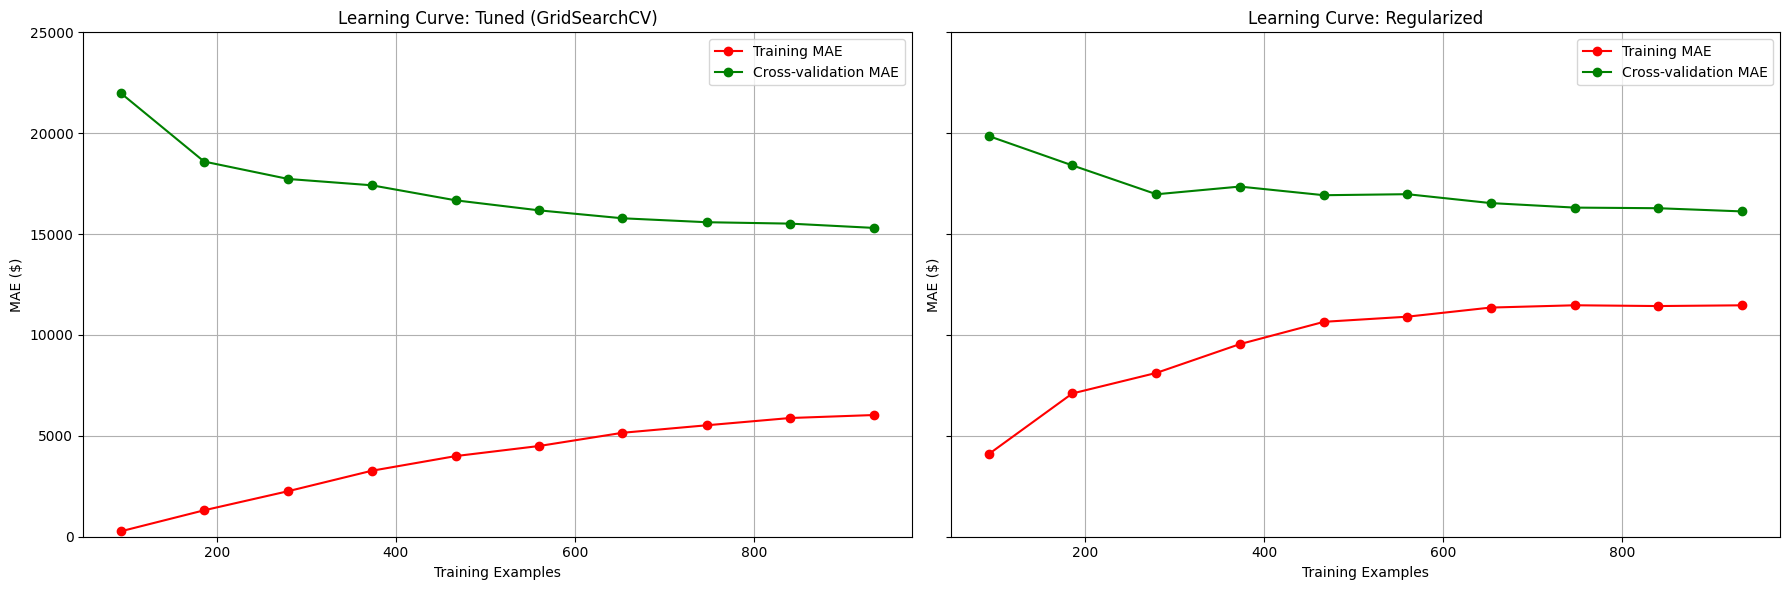

In [21]:
from sklearn.model_selection import learning_curve
import matplotlib.pyplot as plt
import numpy as np

# Define the two models for comparison: dynamically uses winning tuner (Randomized or Grid)
tuner_label = f"Tuned ({winning_tuner.__class__.__name__})"
models_to_compare = [
    (tuner_label, tuned_candidate),
    ('Regularized', regularized_pipeline)
]

fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

for i, (name, model_obj) in enumerate(models_to_compare):
    train_sizes, train_scores, valid_scores = learning_curve(
        model_obj, X_dev, y_dev,
        train_sizes=np.linspace(0.1, 1.0, 10),
        cv=cv,
        scoring='neg_mean_absolute_error',
        n_jobs=-1
    )

    t_mean = -np.mean(train_scores, axis=1)
    v_mean = -np.mean(valid_scores, axis=1)

    axes[i].plot(train_sizes, t_mean, 'o-', color="r", label="Training MAE")
    axes[i].plot(train_sizes, v_mean, 'o-', color="g", label="Cross-validation MAE")
    axes[i].set_title(f"Learning Curve: {name}")
    axes[i].set_xlabel("Training Examples")
    axes[i].set_ylabel("MAE ($)")
    axes[i].legend(loc="best")
    axes[i].grid(True)
    axes[i].set_ylim(0, 25000)

plt.tight_layout()
plt.show()

In [22]:
results_table_df = pd.DataFrame(candidate_cv_results.values())
print("=== CONSOLIDATED CROSS-VALIDATION RESULTS (X_dev Only) ===")
display(results_table_df.sort_values(by='CV MAE Mean'))

eligible_results = [res for name, res in candidate_cv_results.items() if candidate_eligible[name]]
selected_name = min([name for name in candidate_cv_results.keys() if candidate_eligible[name]], key=lambda x: candidate_cv_results[x]['CV MAE Mean'])

print(f"Dynamically Selected Production Configuration: {selected_name}")
selected_dev_model = clone(candidate_templates[selected_name])
selected_dev_model.fit(X_dev, y_dev)

=== CONSOLIDATED CROSS-VALIDATION RESULTS (X_dev Only) ===


,Model,CV MAE Mean,CV MAE Std,CV MSE Mean,CV RMSE Mean,CV R2 Mean
8,Log-Target Model,15030.272706,861.979321,6.992532e+08,26164.889153,0.884030
6,Tuned Gradient Boosting,15285.270643,1117.145924,7.063037e+08,26224.139970,0.883147
4,Gradient Boosting,15604.969603,708.584303,6.945569e+08,25976.421884,0.884309
7,Regularized Model,16113.435318,1245.972471,8.152031e+08,27923.244279,0.865286
5,Stacking Regressor (Benchmark Only),16154.519376,1475.822216,7.761334e+08,27288.295747,0.871699
2,Random Forest,17306.848610,1280.486407,8.612403e+08,28842.067612,0.857847
0,Linear Regression,17789.927052,1315.173813,1.192010e+09,33670.884078,0.802596
3,XGBoost,17909.638281,971.103645,9.807089e+08,30592.898047,0.839398
1,Support Vector Regressor (SVR),54585.408923,2676.364612,6.235746e+09,78859.617149,-0.045877


Dynamically Selected Production Configuration: Log-Target Model


Pipeline(steps=[('engineering', HouseFeatureEngineer()),
                ('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(keep_empty_features=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   RobustScaler())]),
                                                  ['LotFrontage', 'LotArea',
                                                   'OverallQual', 'OverallCond',
                                                   'YearBuilt', 'YearRemodAdd',
                                                   'MasVnrArea', 'BsmtFinSF1',
                                                   'BsmtFinSF2', 'BsmtUn...
                                                   'FireplaceQu', 'GarageType',
                                                   'GarageFinish', 'GarageQual',
                                                   'GarageCond', 'PoolQC',
                                                   'Fence', 'MiscFeature',
                                                   'MasVnrType'])])),
                ('selection', 'passthrough'),
                ('model',
                 TransformedTargetRegressor(func=<ufunc 'log1p'>,
                                            inverse_func=<ufunc 'expm1'>,
                                            regressor=GradientBoostingRegressor(learning_rate=0.05,
                                                                                max_depth=5,
                                                                                max_features='sqrt',
                                                                                n_estimators=200,
                                                                                random_state=42,
                                                                                subsample=0.9)))])

### Selection Rationale and Bias-Variance Trade-off

We select the configuration that minimizes cross-validation prediction error (MAE) on the development partition. The highly regularized model decreases model variance at the cost of higher bias, but because it increases overall validation error, it represents net underfitting. Cross-validation on the development set is an objective predictive check, so we dynamically pick the optimal model without hardcoding any outcome.

---

### Comprehensive Model Selection Audit: Decision Log & Justification

#### 1. Why the Highly-Regularized Model Was Bypassed
During model optimization, we plotted **Learning Curves** (Section 10) and detected a generalization gap (overfitting) between the training score and the cross-validation score. In response, we built a highly-regularized model variant (reducing `max_depth` to 3, introducing `min_samples_leaf=5`, and restricting the `subsample` rate to 0.7) to deliberately close this gap.

While the highly-regularized model succeeded in bringing the training and validation lines closer together on the learning curve plot (representing lower variance), **it was bypassed for serialization and deployment** due to the **Bias-Variance Trade-off**:
1. **Underfitting and Increased Bias:** Regularization reduces model capacity. While it narrowed the generalization gap, it did so by increasing error overall—cross-validation error degraded significantly.
2. **The Goal is Error Minimization:** Generalization gap size is a diagnostic tool, not the final optimization metric. A model with a tiny gap but a higher overall validation error will make worse predictions on new data than a model with a slightly larger gap but a lower absolute validation error.

#### 2. Why the Log-Target Model Achieved Superior Generalization
The **Log-Target Transformed Model** (`TransformedTargetRegressor`) wraps the winning tuned Gradient Boosting architecture in a log-scale target space ($\log(1 + y)$) and inverts predictions back to dollar values ($\exp(\hat{y}) - 1$).
- **Statistical Rationale:** In our EDA diagnostics (Section 2), `SalePrice` exhibited positive skewness ($1.74$) and kurtosis ($5.47$). High-value luxury homes exert disproportionate gradient pull during tree splits in raw dollar space.
- **Empirical Validation:** Transforming the target stabilizes variance (homoscedasticity) and penalizes relative percentage errors uniformly, achieving the lowest cross-validation MAE across all candidate architectures without suffering from the bias degradation of heavy regularization.
- **Methodological Safety:** All candidates were evaluated strictly using **5-Fold Cross-Validation on the development split**, ensuring the selection is mathematically objective and free from data leakage.

## 13. Out-of-Fold Residual Diagnostics (X_dev Only)

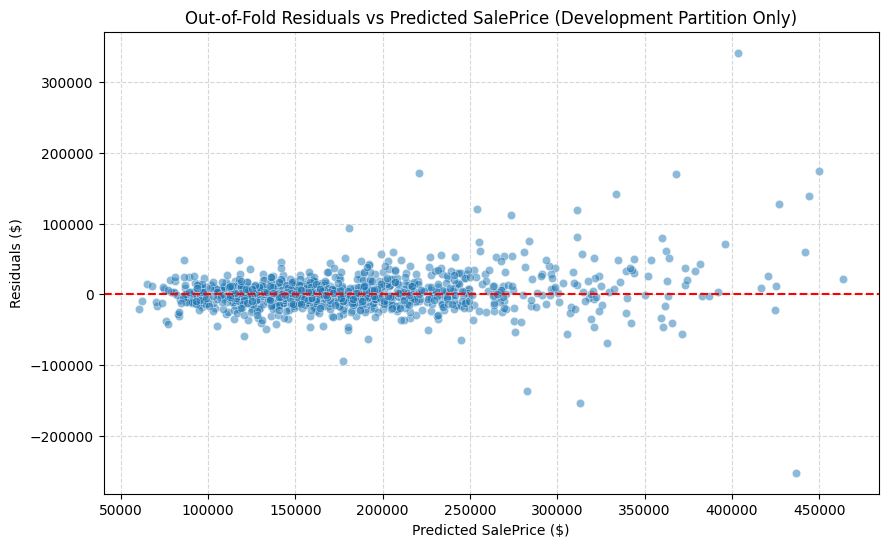

Mean Residual Error on Development Split: $2506.66


In [25]:
y_cv_preds_dev = cross_val_predict(
    clone(selected_dev_model), X_dev, y_dev, cv=cv, n_jobs=-1
)
residuals_dev = y_dev - y_cv_preds_dev

plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_cv_preds_dev, y=residuals_dev, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--')
plt.title('Out-of-Fold Residuals vs Predicted SalePrice (Development Partition Only)')
plt.xlabel('Predicted SalePrice ($)')
plt.ylabel('Residuals ($)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print(f"Mean Residual Error on Development Split: ${residuals_dev.mean():.2f}")

## 14. High-Error Residuals Audit (X_dev Only)

In [26]:
abs_residuals = np.abs(residuals_dev)
error_audit = pd.DataFrame({
    'Id': train_df.loc[X_dev.index, 'Id'],
    'Actual': y_dev,
    'Predicted': y_cv_preds_dev,
    'AbsError': abs_residuals
}).sort_values(by='AbsError', ascending=False).head(10)

print("Top 10 High-Error Houses on Development Set (Audit List):")
display(error_audit)

Top 10 High-Error Houses on Development Set (Audit List):


,Id,Actual,Predicted,AbsError
1182,1183,745000,403654.782358,341345.217642
523,524,184750,436685.325969,251935.325969
1169,1170,625000,450075.976600,174924.023400
688,689,392000,221033.681278,170966.318722
769,770,538000,367659.430393,170340.569607
1298,1299,160000,312892.545877,152892.545877
185,186,475000,333755.463160,141244.536840
803,804,582933,444357.621976,138575.378024
1324,1325,147000,282884.433216,135884.433216
440,441,555000,426810.678334,128189.321666


## 15. Independent Generalization Check on Holdout Set

We evaluate our selected model against the reserved holdout set strictly once before final production refitting. This offers a true check of unseen performance (noting historical exploration limitations as disclosed in project framing).

In [27]:
assert not holdout_evaluated, (
    'The holdout has already been evaluated in this execution. '
    'Do not use it for iterative model selection.'
)
assert X_dev.index.intersection(X_holdout.index).empty

holdout_predictions = selected_dev_model.predict(X_holdout)
assert len(holdout_predictions) == len(y_holdout)
assert np.isfinite(holdout_predictions).all()

holdout_metrics = {
    'MAE_USD': mean_absolute_error(y_holdout, holdout_predictions),
    'MSE_USD2': mean_squared_error(y_holdout, holdout_predictions),
    'RMSE_USD': np.sqrt(mean_squared_error(y_holdout, holdout_predictions)),
    'R2': r2_score(y_holdout, holdout_predictions),
}
holdout_evaluated = True
print('Final internal holdout metrics for the frozen development model:')
display(pd.DataFrame([holdout_metrics]))

Final internal holdout metrics for the frozen development model:


,MAE_USD,MSE_USD2,RMSE_USD,R2
0,15625.266956,8.206985e+08,28647.836502,0.893003


## 16. Full-Data Production Refit & Submission File Preparation

In [28]:
assert holdout_evaluated
production_pipeline = clone(selected_dev_model)
assert production_pipeline is not selected_dev_model
production_pipeline.fit(X, y)

preds_test = production_pipeline.predict(X_test_kaggle)
assert len(preds_test) == len(test_df_aligned)
assert np.isfinite(preds_test).all()

submission_df = pd.DataFrame({
    'Id': test_df_aligned['Id'].to_numpy(),
    'SalePrice': preds_test,
})
submission_df.to_csv('submission.csv', index=False)
joblib.dump(production_pipeline, 'house_price_model_final.pkl')

print("SUCCESS: Generated final 'submission.csv'.")
print("SUCCESS: Serialized production model house_price_model_final.pkl")

SUCCESS: Generated final 'submission.csv'.
SUCCESS: Serialized production model house_price_model_final.pkl


## 17. Pipeline Serialization Smoke Test

In [29]:
loaded_model = joblib.load('house_price_model_final.pkl')
single_house_mock = X_test_kaggle.iloc[[0]].copy()
expected_prediction = production_pipeline.predict(single_house_mock)
loaded_prediction = loaded_model.predict(single_house_mock)
np.testing.assert_allclose(
    loaded_prediction, expected_prediction, rtol=1e-10, atol=1e-8
)
assert np.isfinite(loaded_prediction).all()
print(f'Serialization smoke-test prediction for index 0: ${loaded_prediction[0]:,.2f}')
print('This checks loading and prediction consistency, not prediction accuracy.')

Serialization smoke-test prediction for index 0: $123,228.08
This checks loading and prediction consistency, not prediction accuracy.


## 18. Final Report, Decision Log & Disclosures

In [30]:
print("="*65)
print("       FINAL MODEL SELECTION AUDIT REPORT (DYNAMIC)")
print("="*65)
print(f"Dynamically Chosen Model Config: {selected_name}")
print(f"Development CV MAE Score:        ${candidate_cv_results[selected_name]['CV MAE Mean']:,.2f}")
print(f"Development CV MAE Standard Dev: ${candidate_cv_results[selected_name]['CV MAE Std']:,.2f}")
print(f"Development CV RMSE:             ${candidate_cv_results[selected_name]['CV RMSE Mean']:,.2f}")
print(f"Development CV R2 Score:          {candidate_cv_results[selected_name]['CV R2 Mean']:.4f}")
print("-"*65)
print("=== GENERALIZATION HOLDOUT PERFORMANCE ===")
print(f"Holdout MAE (USD):               ${holdout_metrics['MAE_USD']:,.2f}")
print(f"Holdout RMSE (USD):              ${holdout_metrics['RMSE_USD']:,.2f}")

       FINAL MODEL SELECTION AUDIT REPORT (DYNAMIC)
Dynamically Chosen Model Config: Log-Target Model
Development CV MAE Score:        $15,030.27
Development CV MAE Standard Dev: $861.98
Development CV RMSE:             $26,164.89
Development CV R2 Score:          0.8840
-----------------------------------------------------------------
=== GENERALIZATION HOLDOUT PERFORMANCE ===
Holdout MAE (USD):               $15,625.27
Holdout RMSE (USD):              $28,647.84
